# DSL 504 — NLP Group Assignment 2 — Question 2
## Fine-Tuning RoBERTa vs. BiGRU + Attention for 5-class Amazon Review Rating Prediction

**How to run:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.
All libraries are installed in the first cell. Everything (plots, tables, examples) is produced by the notebook itself.

**Compute switch:** in the *Configuration* cell, `QUICK = True` uses a 40k-review training subset and 1 RoBERTa epoch (finishes in roughly 1–1.5 h on a free T4).
Set `QUICK = False` for the full specification (200,000 training reviews, 2 epochs) — this needs several hours / Colab Pro.
The training-set size used is printed and must be stated in the report.

**Contents**
1. Data loading & two preprocessing pipelines (classic vs. RoBERTa)
2. Baseline: GloVe → 2-layer BiGRU → additive attention pooling → Dropout → Linear
3. RoBERTa: masked mean pooling → Dropout → Linear, full fine-tuning (AdamW, warm-up + linear decay, mixed precision)
4. Ablation: mean pooling vs. first-token pooling
5. Evaluation: Accuracy, Macro-F1, per-class F1, MAE, normalised confusion matrices, adjacent vs. distant errors
6. Qualitative analysis + token-level importance for RoBERTa
7. Auto-generated result summary for the report

## 0. Installation & configuration

In [1]:
!pip install -q datasets transformers accelerate scikit-learn seaborn nltk huggingface_hub

In [2]:
import os, re, json, math, random, time, copy, warnings
from collections import Counter
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from nltk.tokenize import RegexpTokenizer
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel, DataCollatorWithPadding, get_linear_schedule_with_warmup
warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "(no GPU - enable a GPU runtime!)")

# ---------------- Configuration ----------------
QUICK = True                       # False = full assignment size (slow)
SEEDS = [42, 43]                   # >= 2 seeds, results reported as mean +- std
TRAIN_N = 40_000 if QUICK else 200_000
VAL_N, TEST_N = 5_000, 5_000

# baseline (BiGRU + attention)
GLOVE_DIM, MAX_LEN_RNN, MIN_FREQ = 100, 200, 3
RNN_HID, RNN_LAYERS, RNN_DROP, RNN_LR, RNN_BS = 128, 2, 0.3, 1e-3, 256
RNN_EPOCHS, RNN_PATIENCE = (6 if QUICK else 10), 2

# RoBERTa
ROBERTA = "roberta-base"
MAX_LEN_RB, RB_LR, RB_WD, RB_WARMUP, RB_DROP = 256, 2e-5, 0.01, 0.06, 0.1
RB_BS, RB_ACCUM = 32, 1
RB_EPOCHS = 1 if QUICK else 2
EVALS_PER_EPOCH, RB_PATIENCE = 4, 4      # validation every 1/4 epoch; early stop after 4 evals w/o improvement

CLASSES = [1, 2, 3, 4, 5]
OUT_DIR = "q2_outputs"; os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print(f"QUICK={QUICK} | train={TRAIN_N} val={VAL_N} test={TEST_N} | seeds={SEEDS}")

Device: cuda Tesla T4
QUICK=True | train=40000 val=5000 test=5000 | seeds=[42, 43]


## 1. Data loading
`SetFit/amazon_reviews_multi_en`: 5-class star rating (label 0..4 = 1..5 stars).
Title and body are concatenated into a single text. (If the hub version already ships a merged `text` column, that column already contains title + body, otherwise we merge `review_title` + `review_body` ourselves.)
The **validation** set is used for model selection / early stopping; the **test** set is evaluated only once per final model.

In [3]:
ds = load_dataset("SetFit/amazon_reviews_multi_en")
print(ds)

def get_split(name, n=None, seed=0):
    d = ds[name]; cols = d.column_names
    if "review_title" in cols and "review_body" in cols:
        texts = [f"{t}. {b}" for t, b in zip(d["review_title"], d["review_body"])]
    else:
        texts = list(d["text"])
    labels = np.array(d["label"], dtype=np.int64)
    if n is not None and n < len(texts):
        idx = np.random.RandomState(seed).permutation(len(texts))[:n]
        texts = [texts[i] for i in idx]; labels = labels[idx]
    return texts, labels

tr_texts, tr_y = get_split("train", TRAIN_N)
va_texts, va_y = get_split("validation", VAL_N)
te_texts, te_y = get_split("test", TEST_N)
print(len(tr_texts), len(va_texts), len(te_texts))
print("Train class distribution:", np.bincount(tr_y))
print("Example:", tr_texts[0][:300], "->", tr_y[0] + 1, "stars")

README.md:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

train.jsonl: reconstructing file:   0%|          |  0.00B / 47.4MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.18M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
})
40000 5000 5000
Train class distribution: [7997 8002 7874 8105 8022]
Example: Not correct size as advertised -> 2 stars


## 2. Preprocessing pipeline A — classic (for BiGRU + GloVe)
lowercase → strip HTML & URLs → NLTK regexp tokenizer → vocabulary (min-freq) → GloVe embedding matrix → pad/truncate to 200 tokens.

In [4]:
URL_RE, HTML_RE = re.compile(r"https?://\S+|www\.\S+"), re.compile(r"<[^>]+>")
word_tok = RegexpTokenizer(r"[a-z0-9]+(?:'[a-z]+)?|[^\sa-z0-9]")

def clean_text(t):
    t = HTML_RE.sub(" ", t); t = URL_RE.sub(" ", t)
    return re.sub(r"\s+", " ", t.lower()).strip()

def tokenize(t): return word_tok.tokenize(clean_text(t))

t0 = time.time()
tr_tok = [tokenize(t) for t in tr_texts]
va_tok = [tokenize(t) for t in va_texts]
te_tok = [tokenize(t) for t in te_texts]
print(f"Tokenised in {time.time()-t0:.0f}s | mean train length {np.mean([len(t) for t in tr_tok]):.1f} tokens")

PAD, UNK = 0, 1
cnt = Counter(w for toks in tr_tok for w in toks)
itos = ["<pad>", "<unk>"] + [w for w, c in cnt.most_common() if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
print("Vocabulary size (min_freq=%d): %d" % (MIN_FREQ, len(itos)))

def encode(tok_lists, max_len=MAX_LEN_RNN):
    X = np.zeros((len(tok_lists), max_len), dtype=np.int32); L = np.zeros(len(tok_lists), dtype=np.int64)
    for i, toks in enumerate(tok_lists):
        ids = [stoi.get(w, UNK) for w in toks][:max_len]
        X[i, :len(ids)] = ids; L[i] = max(len(ids), 1)
    return X, L

Xtr, Ltr = encode(tr_tok); Xva, Lva = encode(va_tok); Xte, Lte = encode(te_tok)
print(Xtr.shape, Xva.shape, Xte.shape)

Tokenised in 2s | mean train length 38.8 tokens
Vocabulary size (min_freq=3): 11681
(40000, 200) (5000, 200) (5000, 200)


In [5]:
# ---- Pre-trained GloVe (100d, 6B) -> embedding matrix ----
import zipfile
def load_glove_matrix(dim=GLOVE_DIM):
    try:
        from huggingface_hub import hf_hub_download
        path = hf_hub_download("stanfordnlp/glove", "glove.6B.zip")
    except Exception as e:
        print("HF mirror failed (", e, ") -> trying stanford.edu")
        os.system("wget -q -O glove.6B.zip https://nlp.stanford.edu/data/glove.6B.zip"); path = "glove.6B.zip"
    mat = np.random.RandomState(0).normal(0, 0.1, (len(itos), dim)).astype(np.float32)
    mat[PAD] = 0; found = 0
    with zipfile.ZipFile(path) as z, z.open(f"glove.6B.{dim}d.txt") as f:
        for line in f:
            parts = line.decode("utf8").rstrip().split(" ")
            i = stoi.get(parts[0])
            if i is not None:
                mat[i] = np.asarray(parts[1:], dtype=np.float32); found += 1
    print(f"GloVe coverage: {found}/{len(itos)} vocabulary words ({100*found/len(itos):.1f}%)")
    return mat

emb_matrix = load_glove_matrix()

glove.6B.zip: reconstructing file:   0%|          |  0.00B /  862MB            

glove.6B.zip: downloading bytes:           |  0.00B            

GloVe coverage: 11337/11681 vocabulary words (97.1%)


## 3. Preprocessing pipeline B — RoBERTa
`RobertaTokenizerFast` (byte-level BPE) adds `<s>` / `</s>`, truncates to 256 tokens and builds the `attention_mask`.
Padding is **dynamic** (done per batch by `DataCollatorWithPadding`), which speeds training considerably. Raw (un-lowercased) text is used.

In [6]:
tok = AutoTokenizer.from_pretrained(ROBERTA)       # fast tokenizer by default
print(type(tok).__name__)

class ReviewDS(torch.utils.data.Dataset):
    def __init__(self, texts, labels, max_len):
        ids = []
        for i in range(0, len(texts), 20000):
            ids += tok(texts[i:i+20000], truncation=True, max_length=max_len)["input_ids"]
        self.ids, self.y = ids, labels
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        return {"input_ids": self.ids[i], "attention_mask": [1] * len(self.ids[i]), "labels": int(self.y[i])}

collator = DataCollatorWithPadding(tok)
_ds_cache = {}
def get_rb_datasets(max_len):
    if max_len not in _ds_cache:
        t0 = time.time()
        _ds_cache[max_len] = (ReviewDS(tr_texts, tr_y, max_len), ReviewDS(va_texts, va_y, max_len), ReviewDS(te_texts, te_y, max_len))
        print(f"RoBERTa tokenisation (max_len={max_len}) took {time.time()-t0:.0f}s")
    return _ds_cache[max_len]

_a, _b, _c = get_rb_datasets(MAX_LEN_RB)
print("Example tokens:", tok.convert_ids_to_tokens(_a[0]["input_ids"])[:20])
print("Truncated reviews (train): %.1f%%" % (100 * np.mean([len(x) >= MAX_LEN_RB for x in _a.ids])))

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

RobertaTokenizer
RoBERTa tokenisation (max_len=256) took 3s
Example tokens: ['<s>', 'Not', 'Ġcorrect', 'Ġsize', 'Ġas', 'Ġadvertised', '</s>']
Truncated reviews (train): 0.4%


## 4. Metrics

In [7]:
def compute_metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return dict(acc=accuracy_score(y, p), macro_f1=f1_score(y, p, average="macro"),
                mae=float(np.abs(y - p).mean()), per_class_f1=f1_score(y, p, average=None, labels=range(5)))

def fmt(m): return f"acc={m['acc']:.4f} macroF1={m['macro_f1']:.4f} MAE={m['mae']:.4f}"

## 5. Baseline model — Embedding(GloVe) → 2-layer BiGRU → Additive attention pooling → Dropout → Linear(5)
* Embedding layer **frozen for the first epoch**, then unfrozen.
* Adam (lr 1e-3), gradient clipping (max-norm 1.0), early stopping on validation Macro-F1, Cross-Entropy loss.

In [8]:
class BiGRUAttn(nn.Module):
    def __init__(self, emb_matrix, hid=128, layers=2, drop=0.3, ncls=5):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=True, padding_idx=PAD)
        self.gru = nn.GRU(emb_matrix.shape[1], hid, num_layers=layers, batch_first=True,
                          bidirectional=True, dropout=drop if layers > 1 else 0)
        self.att_w = nn.Linear(2 * hid, 2 * hid)           # additive attention: v^T tanh(W h)
        self.att_v = nn.Linear(2 * hid, 1, bias=False)
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(2 * hid, ncls)

    def forward(self, x, lens, return_attn=False):
        e = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(e, lens.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.gru(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        mask = x != PAD
        score = self.att_v(torch.tanh(self.att_w(out))).squeeze(-1).masked_fill(~mask, -1e9)
        a = F.softmax(score, dim=-1)
        pooled = (a.unsqueeze(-1) * out).sum(1)
        logits = self.fc(self.drop(pooled))
        return (logits, a) if return_attn else logits

@torch.no_grad()
def eval_rnn(model, X, L, y, bs=512):
    model.eval(); preds, tot = [], 0.0
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i+bs]).long().to(device); lb = torch.from_numpy(L[i:i+bs])
        logits = model(xb, lb)
        tot += F.cross_entropy(logits, torch.from_numpy(y[i:i+bs]).to(device), reduction="sum").item()
        preds.append(logits.argmax(-1).cpu().numpy())
    p = np.concatenate(preds)
    return tot / len(X), p, compute_metrics(y, p)

def run_baseline(seed, keep_model=False):
    set_seed(seed)
    model = BiGRUAttn(emb_matrix, RNN_HID, RNN_LAYERS, RNN_DROP).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=RNN_LR)
    n_params = sum(p.numel() for p in model.parameters())
    hist, best_f1, best_state, bad = [], -1, None, 0
    rng = np.random.RandomState(seed); t0 = time.time()
    for ep in range(RNN_EPOCHS):
        if ep == 1:
            model.emb.weight.requires_grad = True           # unfreeze embeddings after epoch 1
        model.train(); perm = rng.permutation(len(Xtr)); run_loss, nb = 0.0, 0
        for i in range(0, len(perm), RNN_BS):
            idx = perm[i:i+RNN_BS]
            xb = torch.from_numpy(Xtr[idx]).long().to(device); lb = torch.from_numpy(Ltr[idx])
            yb = torch.from_numpy(tr_y[idx]).to(device)
            loss = F.cross_entropy(model(xb, lb), yb)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            run_loss += loss.item(); nb += 1
        vl, _, vm = eval_rnn(model, Xva, Lva, va_y)
        hist.append(dict(epoch=ep + 1, train_loss=run_loss / nb, val_loss=vl, val_f1=vm["macro_f1"], val_acc=vm["acc"]))
        print(f"[BiGRU seed {seed}] ep {ep+1}: train_loss={run_loss/nb:.4f} val_loss={vl:.4f} val_{fmt(vm)}")
        if vm["macro_f1"] > best_f1:
            best_f1, bad = vm["macro_f1"], 0; best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= RNN_PATIENCE: print("Early stopping."); break
    model.load_state_dict(best_state)
    _, vp, vm = eval_rnn(model, Xva, Lva, va_y)
    _, tp, tm = eval_rnn(model, Xte, Lte, te_y)         # test touched once, after model selection
    print(f"[BiGRU seed {seed}] TEST: {fmt(tm)} | params={n_params:,} | {time.time()-t0:.0f}s")
    res = dict(hist=hist, val=vm, test=tm, test_preds=tp, val_preds=vp, params=n_params)
    if keep_model: res["model"] = model
    return res

In [9]:
base_runs = {}
for s in SEEDS:
    base_runs[s] = run_baseline(s, keep_model=(s == SEEDS[0]))

[BiGRU seed 42] ep 1: train_loss=1.3926 val_loss=1.2702 val_acc=0.4408 macroF1=0.4061 MAE=0.8706
[BiGRU seed 42] ep 2: train_loss=1.2294 val_loss=1.2063 val_acc=0.4606 macroF1=0.4501 MAE=0.6892
[BiGRU seed 42] ep 3: train_loss=1.1333 val_loss=1.0960 val_acc=0.5194 macroF1=0.4991 MAE=0.6392
[BiGRU seed 42] ep 4: train_loss=1.0713 val_loss=1.1493 val_acc=0.4996 macroF1=0.4688 MAE=0.6954
[BiGRU seed 42] ep 5: train_loss=1.0325 val_loss=1.0742 val_acc=0.5376 macroF1=0.5200 MAE=0.6106
[BiGRU seed 42] ep 6: train_loss=1.0000 val_loss=1.0910 val_acc=0.5350 macroF1=0.5218 MAE=0.6172
[BiGRU seed 42] TEST: acc=0.5342 macroF1=0.5217 MAE=0.6216 | params=1,708,521 | 96s
[BiGRU seed 43] ep 1: train_loss=1.4044 val_loss=1.3018 val_acc=0.4190 macroF1=0.4234 MAE=0.8074
[BiGRU seed 43] ep 2: train_loss=1.2275 val_loss=1.1398 val_acc=0.5110 macroF1=0.5065 MAE=0.6460
[BiGRU seed 43] ep 3: train_loss=1.1242 val_loss=1.1085 val_acc=0.5206 macroF1=0.5069 MAE=0.6374
[BiGRU seed 43] ep 4: train_loss=1.0694 val

## 6. RoBERTa model — masked mean pooling → Dropout → Linear(5), fine-tuned end-to-end
AdamW (lr 2e-5, weight-decay 0.01, no decay on bias/LayerNorm), 6 % linear warm-up then linear decay, mixed precision (fp16 on T4 / bf16 on Ampere+), gradient clipping,
validation every ¼ epoch with checkpoint selection and early stopping on validation Macro-F1.

In [10]:
class RobertaCls(nn.Module):
    def __init__(self, name=ROBERTA, pooling="mean", drop=RB_DROP, ncls=5):
        super().__init__()
        self.enc = AutoModel.from_pretrained(name, add_pooling_layer=False)
        self.pooling = pooling
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(self.enc.config.hidden_size, ncls)

    def forward(self, input_ids=None, attention_mask=None, inputs_embeds=None):
        h = self.enc(input_ids=input_ids, inputs_embeds=inputs_embeds, attention_mask=attention_mask).last_hidden_state
        if self.pooling == "mean":                                   # masked mean over non-padded tokens
            m = attention_mask.unsqueeze(-1).to(h.dtype)
            pooled = (h * m).sum(1) / m.sum(1).clamp(min=1)
        else:                                                        # first-token (<s>) pooling for the ablation
            pooled = h[:, 0]
        return self.fc(self.drop(pooled))

use_cuda = device.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (use_cuda and torch.cuda.get_device_capability()[0] >= 8) else torch.float16
print("Mixed precision dtype:", AMP_DTYPE)

@torch.no_grad()
def eval_rb(model, ds_, bs=128):
    model.eval(); loader = torch.utils.data.DataLoader(ds_, batch_size=bs, collate_fn=collator)
    preds, tot, ys = [], 0.0, []
    for b in loader:
        b = {k: v.to(device) for k, v in b.items()}
        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=use_cuda):
            logits = model(b["input_ids"], b["attention_mask"])
        tot += F.cross_entropy(logits.float(), b["labels"], reduction="sum").item()
        preds.append(logits.argmax(-1).cpu().numpy()); ys.append(b["labels"].cpu().numpy())
    p, y = np.concatenate(preds), np.concatenate(ys)
    return tot / len(y), p, compute_metrics(y, p)

def run_roberta(seed, pooling="mean", max_len=MAX_LEN_RB, keep_model=False, eval_test=True, tag="RoBERTa"):
    set_seed(seed); t0 = time.time()
    tr_ds, va_ds, te_ds = get_rb_datasets(max_len)
    g = torch.Generator(); g.manual_seed(seed)
    loader = torch.utils.data.DataLoader(tr_ds, batch_size=RB_BS, shuffle=True, collate_fn=collator, generator=g, num_workers=2)
    model = RobertaCls(pooling=pooling).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    no_decay = ("bias", "LayerNorm.weight")
    groups = [{"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], "weight_decay": RB_WD},
              {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=RB_LR)
    total_steps = math.ceil(len(loader) / RB_ACCUM) * RB_EPOCHS
    sched = get_linear_schedule_with_warmup(opt, int(RB_WARMUP * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda and AMP_DTYPE == torch.float16)
    eval_every = max(1, total_steps // (RB_EPOCHS * EVALS_PER_EPOCH))
    hist, best_f1, best_state, bad, step, run_loss, run_n, stop = [], -1, None, 0, 0, 0.0, 0, False
    print(f"[{tag} seed {seed}] steps={total_steps} eval_every={eval_every} params={n_params:,}")

    def do_eval():
        nonlocal best_f1, best_state, bad, run_loss, run_n, stop
        vl, _, vm = eval_rb(model, va_ds); model.train()
        hist.append(dict(step=step, train_loss=run_loss / max(run_n, 1), val_loss=vl, val_f1=vm["macro_f1"], val_acc=vm["acc"]))
        print(f"[{tag} seed {seed}] step {step}/{total_steps}: train_loss={hist[-1]['train_loss']:.4f} val_loss={vl:.4f} val_{fmt(vm)}")
        run_loss, run_n = 0.0, 0
        if vm["macro_f1"] > best_f1:
            best_f1, bad = vm["macro_f1"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= RB_PATIENCE: print("Early stopping."); stop = True

    model.train(); micro = 0
    for ep in range(RB_EPOCHS):
        for b in loader:
            b = {k: v.to(device) for k, v in b.items()}
            with torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=use_cuda):
                logits = model(b["input_ids"], b["attention_mask"])
            loss = F.cross_entropy(logits.float(), b["labels"])
            scaler.scale(loss / RB_ACCUM).backward(); micro += 1
            run_loss += loss.item(); run_n += 1
            if micro % RB_ACCUM == 0:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step(); step += 1
                if step % eval_every == 0 or step == total_steps:
                    do_eval()
                    if stop: break
        if stop: break
    model.load_state_dict(best_state); model.to(device)
    _, vp, vm = eval_rb(model, va_ds)
    res = dict(hist=hist, val=vm, val_preds=vp, params=n_params, pooling=pooling, max_len=max_len)
    if eval_test:                                              # test set touched once for each final model
        _, tp, tm = eval_rb(model, te_ds); res.update(test=tm, test_preds=tp)
        print(f"[{tag} seed {seed}] TEST: {fmt(tm)} | {time.time()-t0:.0f}s")
    else:
        print(f"[{tag} seed {seed}] VAL (best): {fmt(vm)} | {time.time()-t0:.0f}s")
    if keep_model: res["model"] = model
    else: del model
    del opt; torch.cuda.empty_cache()
    return res

Mixed precision dtype: torch.float16


In [11]:
rb_runs = {}
for s in SEEDS:
    rb_runs[s] = run_roberta(s, "mean", keep_model=(s == SEEDS[0]))

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[RoBERTa seed 42] steps=1250 eval_every=312 params=124,058,885
[RoBERTa seed 42] step 312/1250: train_loss=1.1654 val_loss=1.0377 val_acc=0.5578 macroF1=0.5389 MAE=0.5512
[RoBERTa seed 42] step 624/1250: train_loss=1.0125 val_loss=0.9613 val_acc=0.5772 macroF1=0.5737 MAE=0.4984
[RoBERTa seed 42] step 936/1250: train_loss=0.9658 val_loss=0.9672 val_acc=0.5826 macroF1=0.5735 MAE=0.4986
[RoBERTa seed 42] step 1248/1250: train_loss=0.9394 val_loss=0.9496 val_acc=0.5900 macroF1=0.5869 MAE=0.4820
[RoBERTa seed 42] step 1250/1250: train_loss=0.9131 val_loss=0.9496 val_acc=0.5904 macroF1=0.5873 MAE=0.4818
[RoBERTa seed 42] TEST: acc=0.5888 macroF1=0.5859 MAE=0.4752 | 433s


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[RoBERTa seed 43] steps=1250 eval_every=312 params=124,058,885
[RoBERTa seed 43] step 312/1250: train_loss=1.1563 val_loss=0.9892 val_acc=0.5700 macroF1=0.5662 MAE=0.5156
[RoBERTa seed 43] step 624/1250: train_loss=0.9899 val_loss=0.9771 val_acc=0.5704 macroF1=0.5644 MAE=0.5162
[RoBERTa seed 43] step 936/1250: train_loss=0.9659 val_loss=0.9617 val_acc=0.5842 macroF1=0.5743 MAE=0.5022
[RoBERTa seed 43] step 1248/1250: train_loss=0.9291 val_loss=0.9515 val_acc=0.5880 macroF1=0.5835 MAE=0.4856
[RoBERTa seed 43] step 1250/1250: train_loss=1.0704 val_loss=0.9515 val_acc=0.5878 macroF1=0.5833 MAE=0.4858
[RoBERTa seed 43] TEST: acc=0.5962 macroF1=0.5933 MAE=0.4678 | 427s


## 7. Ablation — mean pooling vs. first-token (`<s>`) pooling for RoBERTa
To keep the test set "touched once", the ablation is compared on the **validation** set (same seed, same budget).

In [12]:
abl = run_roberta(SEEDS[0], pooling="first", eval_test=False, tag="RoBERTa-first-token")
abl_df = pd.DataFrame({
    "Pooling": ["Mean pooling (ours)", "First-token <s> pooling"],
    "Val Accuracy": [rb_runs[SEEDS[0]]["val"]["acc"], abl["val"]["acc"]],
    "Val Macro-F1": [rb_runs[SEEDS[0]]["val"]["macro_f1"], abl["val"]["macro_f1"]],
    "Val MAE": [rb_runs[SEEDS[0]]["val"]["mae"], abl["val"]["mae"]]}).round(4)
display(abl_df); abl_df.to_csv(f"{OUT_DIR}/ablation_pooling.csv", index=False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[RoBERTa-first-token seed 42] steps=1250 eval_every=312 params=124,058,885
[RoBERTa-first-token seed 42] step 312/1250: train_loss=1.1923 val_loss=1.0585 val_acc=0.5540 macroF1=0.5279 MAE=0.5508
[RoBERTa-first-token seed 42] step 624/1250: train_loss=1.0175 val_loss=0.9666 val_acc=0.5764 macroF1=0.5699 MAE=0.5032
[RoBERTa-first-token seed 42] step 936/1250: train_loss=0.9713 val_loss=0.9643 val_acc=0.5816 macroF1=0.5710 MAE=0.5016
[RoBERTa-first-token seed 42] step 1248/1250: train_loss=0.9428 val_loss=0.9491 val_acc=0.5820 macroF1=0.5784 MAE=0.4946
[RoBERTa-first-token seed 42] step 1250/1250: train_loss=0.9094 val_loss=0.9491 val_acc=0.5820 macroF1=0.5783 MAE=0.4948
[RoBERTa-first-token seed 42] VAL (best): acc=0.5820 macroF1=0.5784 MAE=0.4946 | 414s


,Pooling,Val Accuracy,Val Macro-F1,Val MAE
0,Mean pooling (ours),0.5904,0.5873,0.4818
1,First-token <s> pooling,0.5820,0.5784,0.4946


## 8. Quantitative evaluation (test set)

In [13]:
def agg(runs, key):
    vals = np.array([r["test"][key] for r in runs.values()]); return vals.mean(), vals.std()

rows = []
for name, runs in [("BiGRU + Attention (GloVe)", base_runs), ("RoBERTa-base (mean pooling)", rb_runs)]:
    row = {"Model": name, "Params": f"{list(runs.values())[0]['params']:,}"}
    for k, lab in [("acc", "Accuracy"), ("macro_f1", "Macro-F1"), ("mae", "MAE")]:
        m, s = agg(runs, k); row[lab] = f"{m:.4f} ± {s:.4f}"
    rows.append(row)
results_df = pd.DataFrame(rows); display(results_df); results_df.to_csv(f"{OUT_DIR}/test_results.csv", index=False)
print(f"(mean ± std over seeds {SEEDS})")

pc = pd.DataFrame({
    "Model": ["BiGRU + Attention", "RoBERTa-base"],
    **{f"F1 {c}★": [np.mean([r["test"]["per_class_f1"][i] for r in runs.values()]) for runs in (base_runs, rb_runs)]
       for i, c in enumerate(CLASSES)}}).round(4)
display(pc); pc.to_csv(f"{OUT_DIR}/per_class_f1.csv", index=False)

,Model,Params,Accuracy,Macro-F1,MAE
0,BiGRU + Attention (GloVe),"1,708,521",0.5338 ± 0.0004,0.5244 ± 0.0026,0.6048 ± 0.0168
1,RoBERTa-base (mean pooling),"124,058,885",0.5925 ± 0.0037,0.5896 ± 0.0037,0.4715 ± 0.0037


(mean ± std over seeds [42, 43])


,Model,F1 1★,F1 2★,F1 3★,F1 4★,F1 5★
0,BiGRU + Attention,0.6487,0.4296,0.3886,0.4504,0.7047
1,RoBERTa-base,0.6897,0.4922,0.4599,0.5395,0.7667


### Training / validation curves (loss and Macro-F1)

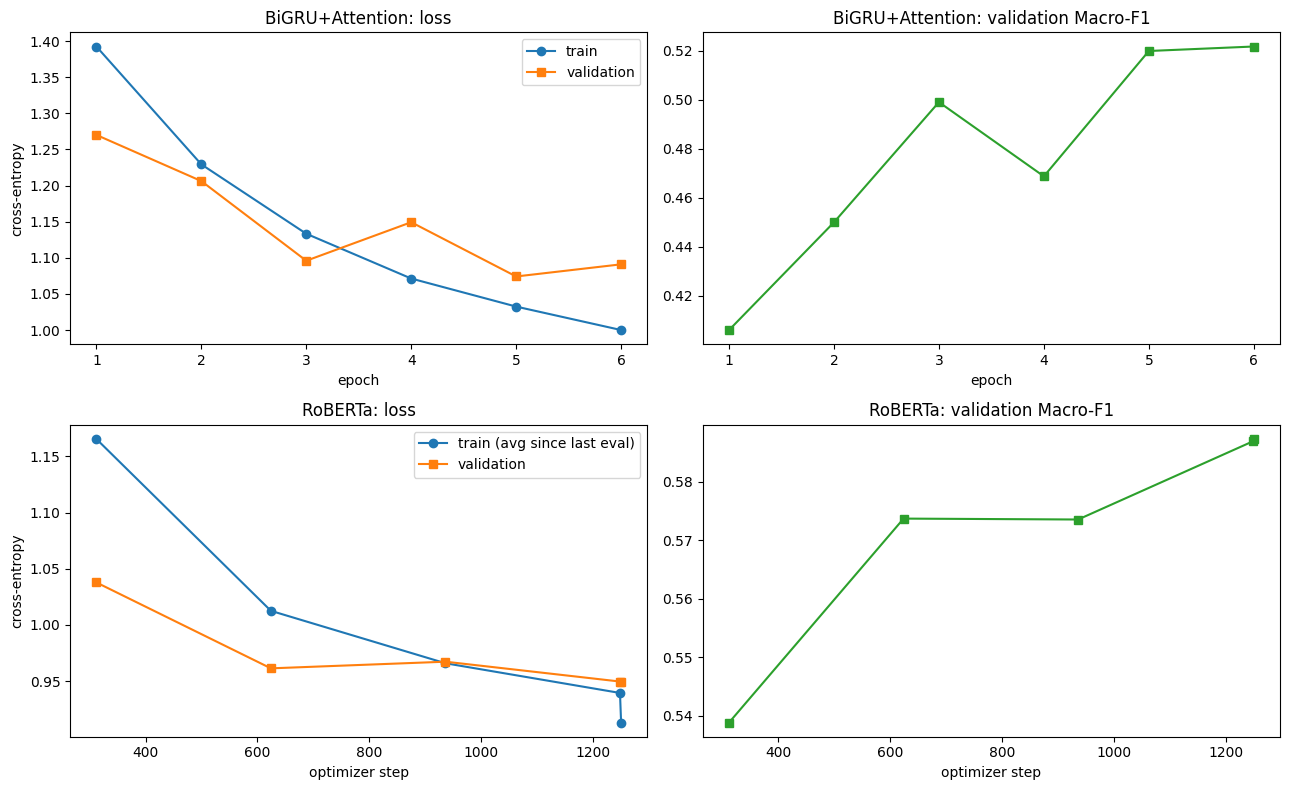

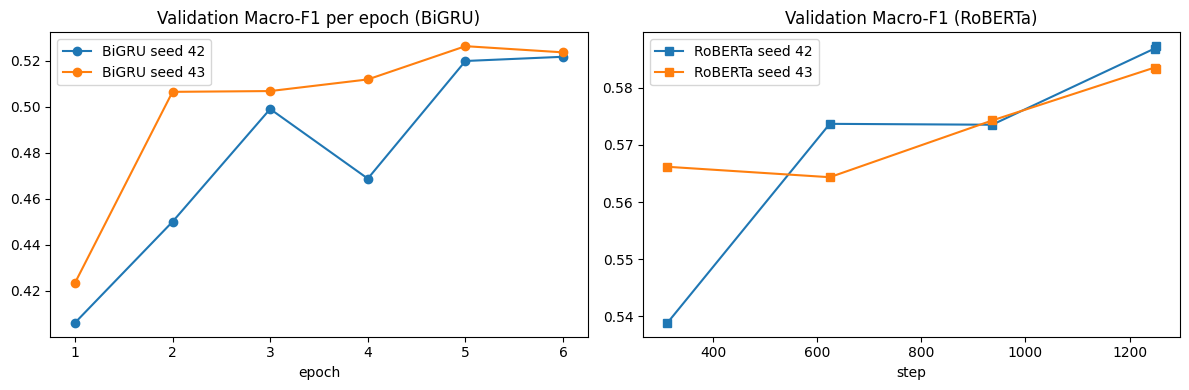

In [14]:
s0 = SEEDS[0]
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
hb = pd.DataFrame(base_runs[s0]["hist"]); hr = pd.DataFrame(rb_runs[s0]["hist"])
ax[0, 0].plot(hb.epoch, hb.train_loss, "o-", label="train"); ax[0, 0].plot(hb.epoch, hb.val_loss, "s-", label="validation")
ax[0, 0].set(title="BiGRU+Attention: loss", xlabel="epoch", ylabel="cross-entropy"); ax[0, 0].legend()
ax[0, 1].plot(hb.epoch, hb.val_f1, "s-", c="tab:green"); ax[0, 1].set(title="BiGRU+Attention: validation Macro-F1", xlabel="epoch")
ax[1, 0].plot(hr.step, hr.train_loss, "o-", label="train (avg since last eval)"); ax[1, 0].plot(hr.step, hr.val_loss, "s-", label="validation")
ax[1, 0].set(title="RoBERTa: loss", xlabel="optimizer step", ylabel="cross-entropy"); ax[1, 0].legend()
ax[1, 1].plot(hr.step, hr.val_f1, "s-", c="tab:green"); ax[1, 1].set(title="RoBERTa: validation Macro-F1", xlabel="optimizer step")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s in SEEDS:
    h = pd.DataFrame(base_runs[s]["hist"]); ax[0].plot(h.epoch, h.val_f1, "o-", label=f"BiGRU seed {s}")
    h = pd.DataFrame(rb_runs[s]["hist"]); ax[1].plot(h.step, h.val_f1, "s-", label=f"RoBERTa seed {s}")
ax[0].set(title="Validation Macro-F1 per epoch (BiGRU)", xlabel="epoch"); ax[1].set(title="Validation Macro-F1 (RoBERTa)", xlabel="step")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/val_f1_all_seeds.png", dpi=150); plt.show()

### Normalised confusion matrices and adjacent-vs-distant errors (seed 42 predictions)

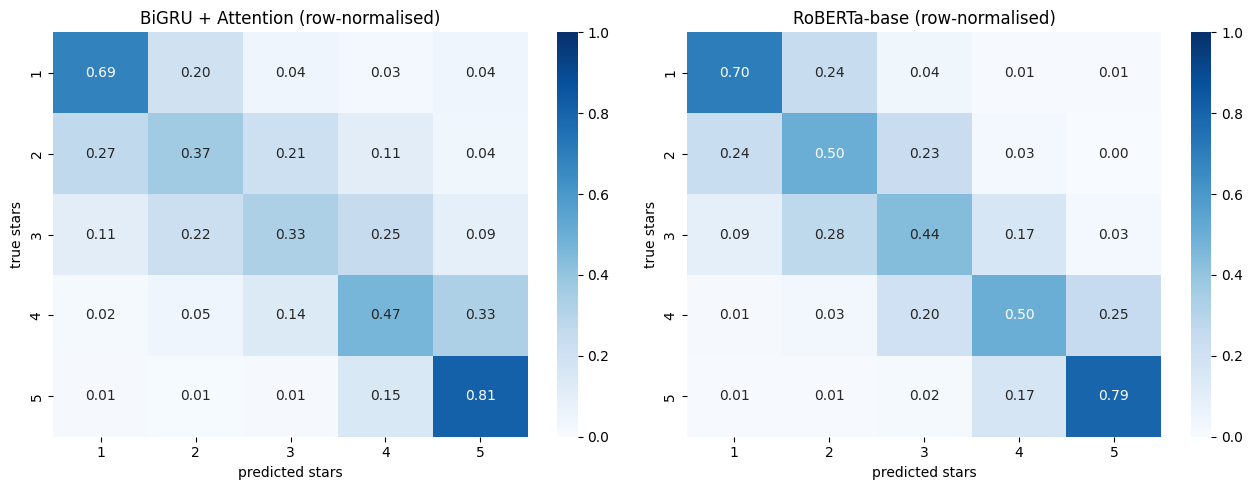

,Exact (%),Adjacent error ±1 (%),Distant error ≥2 (%),Extreme 1↔5 (%),Share of errors that are adjacent (%)
BiGRU + Attention,53.42,35.26,11.32,1.20,75.70
RoBERTa-base,58.88,35.72,5.40,0.24,86.87


In [15]:
pb, pr = base_runs[s0]["test_preds"], rb_runs[s0]["test_preds"]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, p, name in [(ax[0], pb, "BiGRU + Attention"), (ax[1], pr, "RoBERTa-base")]:
    cm = confusion_matrix(te_y, p, labels=range(5), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES, ax=a)
    a.set(title=f"{name} (row-normalised)", xlabel="predicted stars", ylabel="true stars")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrices.png", dpi=150); plt.show()

def err_profile(p):
    d = np.abs(te_y - p); wrong = d > 0
    return {"Exact (%)": 100 * (d == 0).mean(), "Adjacent error ±1 (%)": 100 * (d == 1).mean(),
            "Distant error ≥2 (%)": 100 * (d >= 2).mean(), "Extreme 1↔5 (%)": 100 * (d == 4).mean(),
            "Share of errors that are adjacent (%)": 100 * (d[wrong] == 1).mean()}
err_df = pd.DataFrame({"BiGRU + Attention": err_profile(pb), "RoBERTa-base": err_profile(pr)}).T.round(2)
display(err_df); err_df.to_csv(f"{OUT_DIR}/error_profile.csv")

## 9. Qualitative analysis
Test examples where the baseline fails but RoBERTa succeeds (≥5) and the opposite (≥2). Heuristic cues (negation, contrast / mixed sentiment, length, rare words) are printed to help form hypotheses.

In [16]:
NEG = re.compile(r"\b(not|no|never|n't|none|nothing|hardly|without|cannot)\b|n't")
CONTRAST = re.compile(r"\b(but|however|although|though|yet|except|unfortunately|despite)\b")

def cues(i):
    toks = te_tok[i]; c = []
    if NEG.search(te_texts[i].lower()): c.append("negation")
    if CONTRAST.search(te_texts[i].lower()): c.append("contrast/mixed sentiment")
    if len(toks) > 150: c.append("long review (%d tokens)" % len(toks))
    oov = np.mean([w not in stoi for w in toks]) if toks else 0
    if oov > 0.08: c.append("many OOV/misspelled tokens for baseline (%.0f%%)" % (100 * oov))
    if "!" in te_texts[i] and te_y[i] <= 1: c.append("exclamation in negative review (possible sarcasm)")
    return c or ["no obvious surface cue"]

rng = np.random.RandomState(0)
rb_win = rng.permutation(np.where((pb != te_y) & (pr == te_y))[0])[:7]
bl_win = rng.permutation(np.where((pb == te_y) & (pr != te_y))[0])[:3]
print(f"Baseline wrong & RoBERTa right: {((pb != te_y) & (pr == te_y)).sum()} | Baseline right & RoBERTa wrong: {((pb == te_y) & (pr != te_y)).sum()}\n")

def show(idx, title):
    print("=" * 100); print(title); print("=" * 100); recs = []
    for i in idx:
        print(f"[test #{i}] TRUE={te_y[i]+1}★  BiGRU={pb[i]+1}★  RoBERTa={pr[i]+1}★  | cues: {', '.join(cues(i))}")
        print("   ", te_texts[i][:450].replace("\n", " "), "\n")
        recs.append(dict(idx=i, text=te_texts[i], true=te_y[i] + 1, bigru=pb[i] + 1, roberta=pr[i] + 1, cues="; ".join(cues(i))))
    return recs
recs = show(rb_win, "BASELINE FAILS, ROBERTA SUCCEEDS") + show(bl_win, "ROBERTA FAILS, BASELINE SUCCEEDS")
pd.DataFrame(recs).to_csv(f"{OUT_DIR}/qualitative_examples.csv", index=False)

Baseline wrong & RoBERTa right: 725 | Baseline right & RoBERTa wrong: 452

BASELINE FAILS, ROBERTA SUCCEEDS
[test #3298] TRUE=4★  BiGRU=3★  RoBERTa=4★  | cues: many OOV/misspelled tokens for baseline (9%)
    Enjoyed the way this mystery unfolded. Based in Canada about a frozen corpse found on along a USA roadway. Hunter an ex detective turned truck driver is thrown into the middle of this investigation to help out his fellow truckers. 

[test #2818] TRUE=3★  BiGRU=2★  RoBERTa=3★  | cues: negation
    When responses are typed answers are slow in appearing. The graphics and pictures aren't always clear a r. 

[test #3444] TRUE=4★  BiGRU=3★  RoBERTa=4★  | cues: negation, contrast/mixed sentiment
    They are ok, not hard but worth the money 

[test #2624] TRUE=3★  BiGRU=4★  RoBERTa=3★  | cues: no obvious surface cue
    A bit smaller then what I expected can only use two outlets as the outlets are very close together. If you plug in ones with a big end you can only use two. 

[test #1760

### Token-level importance for RoBERTa (gradient × input-embedding saliency)
Importance of token *i* = |∇ logit(pred class) · embedding_i| (summed over the embedding dimension), normalised to [0, 1].

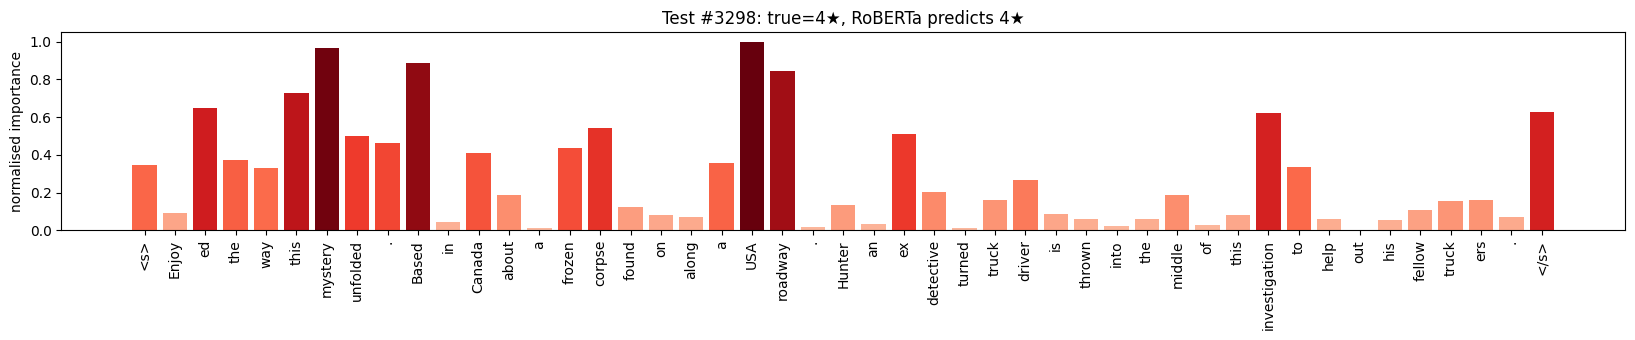

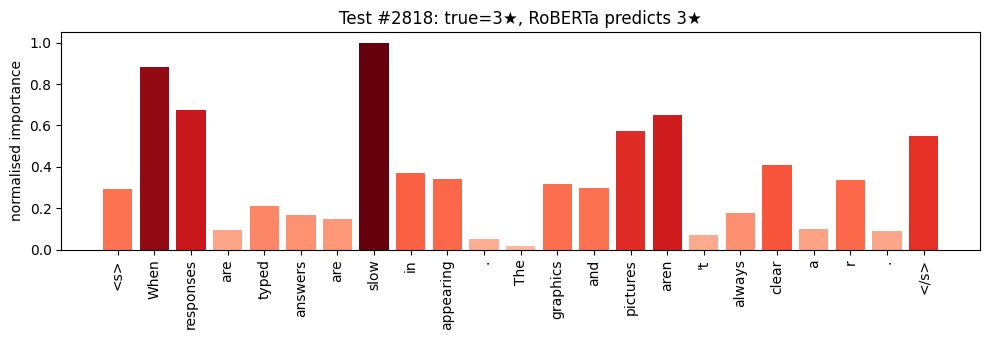

In [17]:
rb_model = rb_runs[s0]["model"]

def saliency(text, model=rb_model):
    model.eval()
    enc = tok(text, truncation=True, max_length=MAX_LEN_RB, return_tensors="pt").to(device)
    emb = model.enc.embeddings.word_embeddings(enc["input_ids"]).detach().requires_grad_(True)
    logits = model(inputs_embeds=emb, attention_mask=enc["attention_mask"])
    c = logits.argmax(-1).item(); model.zero_grad(); logits[0, c].backward()
    imp = (emb.grad * emb).sum(-1).abs()[0].detach().cpu().numpy()
    return tok.convert_ids_to_tokens(enc["input_ids"][0]), imp / (imp.max() + 1e-9), c

def plot_saliency(i, max_tokens=60, fname=None):
    toks, imp, c = saliency(te_texts[i]); toks, imp = toks[:max_tokens], imp[:max_tokens]
    toks = [t.replace("Ġ", "") for t in toks]
    plt.figure(figsize=(max(10, 0.35 * len(toks)), 3.5))
    plt.bar(range(len(toks)), imp, color=plt.cm.Reds(0.25 + 0.75 * imp))
    plt.xticks(range(len(toks)), toks, rotation=90); plt.ylabel("normalised importance")
    plt.title(f"Test #{i}: true={te_y[i]+1}★, RoBERTa predicts {c+1}★"); plt.tight_layout()
    if fname: plt.savefig(fname, dpi=150)
    plt.show()

for k, i in enumerate(list(rb_win[:2])):
    plot_saliency(int(i), fname=f"{OUT_DIR}/saliency_example{k+1}.png")

### Baseline attention-pooling weights for the same example (for comparison)

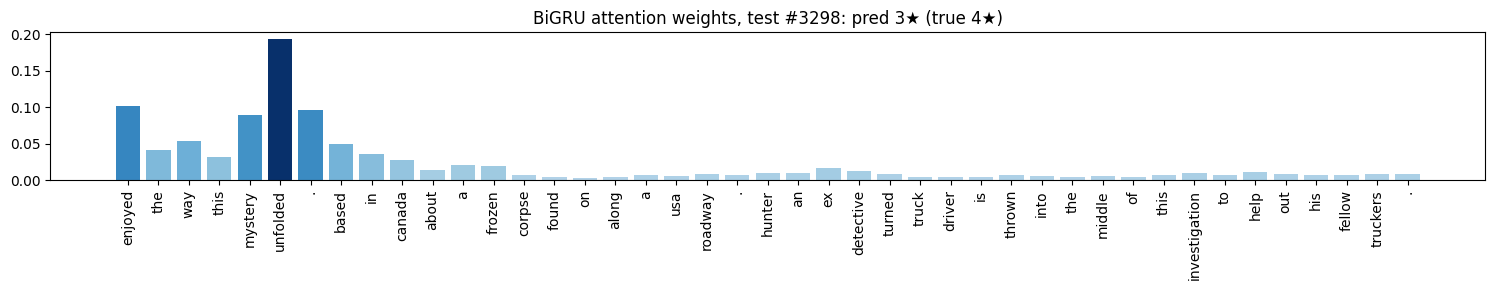

In [18]:
def plot_rnn_attention(i, max_tokens=60):
    m = base_runs[s0]["model"]; m.eval()
    x, l = encode([te_tok[i]]); 
    with torch.no_grad():
        logits, a = m(torch.from_numpy(x).long().to(device), torch.from_numpy(l), return_attn=True)
    n = min(l[0], max_tokens); toks = te_tok[i][:n]; w = a[0, :n].cpu().numpy()
    plt.figure(figsize=(max(10, 0.35 * n), 3)); plt.bar(range(n), w, color=plt.cm.Blues(0.3 + 0.7 * w / (w.max() + 1e-9)))
    plt.xticks(range(n), toks, rotation=90); plt.title(f"BiGRU attention weights, test #{i}: pred {logits.argmax().item()+1}★ (true {te_y[i]+1}★)")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/bigru_attention_example.png", dpi=150); plt.show()
plot_rnn_attention(int(rb_win[0]))

## 10. Auto-generated result summary (copy the numbers into the report)

In [19]:
b_f1, _ = agg(base_runs, "macro_f1"); r_f1, _ = agg(rb_runs, "macro_f1")
b_acc, _ = agg(base_runs, "acc"); r_acc, _ = agg(rb_runs, "acc")
b_mae, _ = agg(base_runs, "mae"); r_mae, _ = agg(rb_runs, "mae")
best_class = int(np.argmax([np.mean([r["test"]["per_class_f1"][i] for r in rb_runs.values()]) -
                            np.mean([r["test"]["per_class_f1"][i] for r in base_runs.values()]) for i in range(5)]))
summary = f"""
SETUP: train={len(tr_texts):,} reviews, val={len(va_texts):,}, test={len(te_texts):,}; seeds={SEEDS}; RoBERTa={ROBERTA}, max_len={MAX_LEN_RB}, {RB_EPOCHS} epoch(s), lr={RB_LR}, wd={RB_WD}, warm-up={RB_WARMUP:.0%}, precision={AMP_DTYPE}.
RESULTS (test, mean over seeds): BiGRU+Attn acc={b_acc:.4f} macroF1={b_f1:.4f} MAE={b_mae:.4f} | RoBERTa acc={r_acc:.4f} macroF1={r_f1:.4f} MAE={r_mae:.4f}.
RoBERTa improves Macro-F1 by {100*(r_f1-b_f1):.2f} points and reduces MAE by {b_mae-r_mae:.3f} stars; the largest per-class F1 gain is for the {CLASSES[best_class]}-star class.
ADJACENT ERRORS: share of errors that are ±1 star -> BiGRU {err_df.loc['BiGRU + Attention','Share of errors that are adjacent (%)']:.1f}%, RoBERTa {err_df.loc['RoBERTa-base','Share of errors that are adjacent (%)']:.1f}%.
ABLATION (val Macro-F1): mean pooling {abl_df.iloc[0]['Val Macro-F1']:.4f} vs first-token {abl_df.iloc[1]['Val Macro-F1']:.4f}.
"""
print(summary); open(f"{OUT_DIR}/summary.txt", "w").write(summary)


SETUP: train=40,000 reviews, val=5,000, test=5,000; seeds=[42, 43]; RoBERTa=roberta-base, max_len=256, 1 epoch(s), lr=2e-05, wd=0.01, warm-up=6%, precision=torch.float16.
RESULTS (test, mean over seeds): BiGRU+Attn acc=0.5338 macroF1=0.5244 MAE=0.6048 | RoBERTa acc=0.5925 macroF1=0.5896 MAE=0.4715.
RoBERTa improves Macro-F1 by 6.52 points and reduces MAE by 0.133 stars; the largest per-class F1 gain is for the 4-star class.
ADJACENT ERRORS: share of errors that are ±1 star -> BiGRU 75.7%, RoBERTa 86.9%.
ABLATION (val Macro-F1): mean pooling 0.5873 vs first-token 0.5784.



578

## 11. Report template (max. 6 pages) — fill in using the outputs above
1. **Introduction** – task, dataset (SetFit/amazon_reviews_multi_en, 5 classes, ordinal), metrics (Accuracy, Macro-F1, MAE).
2. **Preprocessing** – classic pipeline (lower-casing, HTML/URL removal, NLTK regexp tokenizer, min-freq vocab, GloVe-100d matrix, 200 tokens) vs. RoBERTa (`RobertaTokenizerFast`, byte-level BPE, `<s>`/`</s>`, max 256, dynamic padding).
3. **Architectures** – BiGRU(2 layers)+additive attention pooling, frozen→unfrozen embeddings; RoBERTa + masked mean pooling + dropout 0.1 + linear head.
4. **Training** – optimisers, learning rates, warm-up/decay, weight decay, mixed precision, clipping, early stopping, seeds, training-subset size actually used (state it!), curves from §8.
5. **Ablation** – mean vs. first-token pooling (table in §7) and interpretation.
6. **Results** – main table (mean ± std), per-class F1, MAE, confusion matrices, adjacent vs. distant errors.
7. **Qualitative analysis** – the ≥5 / ≥2 examples (negation, contrast, sarcasm, length, misspellings), RoBERTa saliency plots vs. BiGRU attention plot; hypotheses for the differences.
8. **Conclusion & limitations** – subset size, single-epoch fine-tuning, saliency ≠ faithful explanation, only 2 seeds, GloVe-100d vs. fastText, etc.

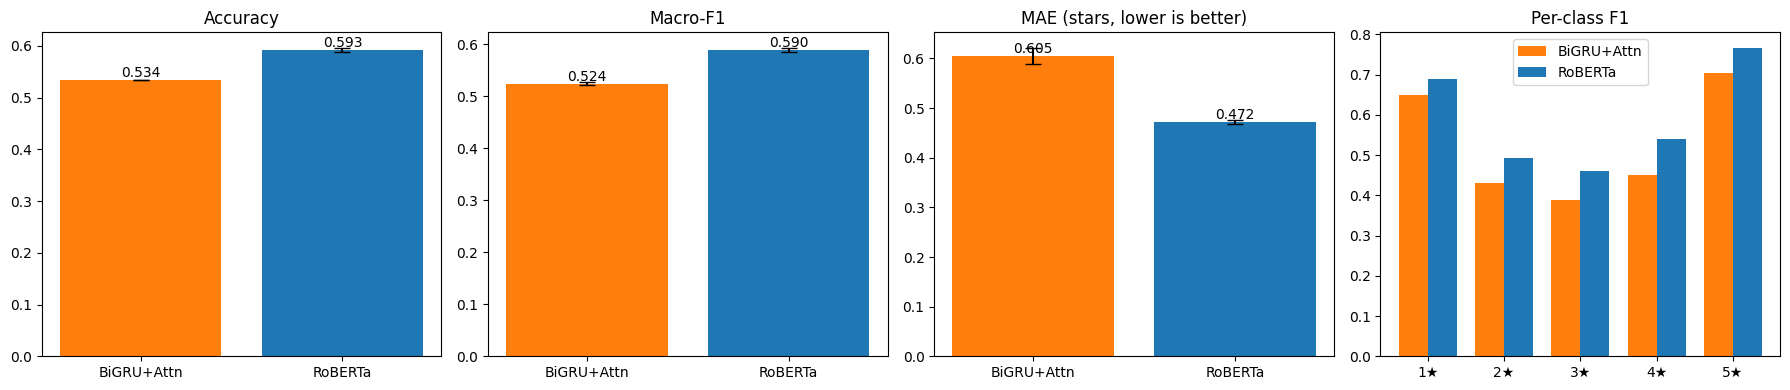

In [20]:
# Overall metrics (mean ± std over seeds) and per-class F1
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
names = ["BiGRU+Attn", "RoBERTa"]; colors = ["tab:orange", "tab:blue"]
for a, (key, lab) in zip(ax[:3], [("acc", "Accuracy"), ("macro_f1", "Macro-F1"), ("mae", "MAE (stars, lower is better)")]):
    vals = [[r["test"][key] for r in runs.values()] for runs in (base_runs, rb_runs)]
    means, stds = [np.mean(v) for v in vals], [np.std(v) for v in vals]
    a.bar(names, means, yerr=stds, capsize=6, color=colors)
    for i, m in enumerate(means): a.text(i, m, f"{m:.3f}", ha="center", va="bottom")
    a.set_title(lab)
x = np.arange(5); w = 0.38
f1_b = np.mean([r["test"]["per_class_f1"] for r in base_runs.values()], axis=0)
f1_r = np.mean([r["test"]["per_class_f1"] for r in rb_runs.values()], axis=0)
ax[3].bar(x - w/2, f1_b, w, label="BiGRU+Attn", color=colors[0]); ax[3].bar(x + w/2, f1_r, w, label="RoBERTa", color=colors[1])
ax[3].set_xticks(x); ax[3].set_xticklabels([f"{c}★" for c in CLASSES]); ax[3].set_title("Per-class F1"); ax[3].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/viz_model_comparison.png", dpi=150); plt.show()

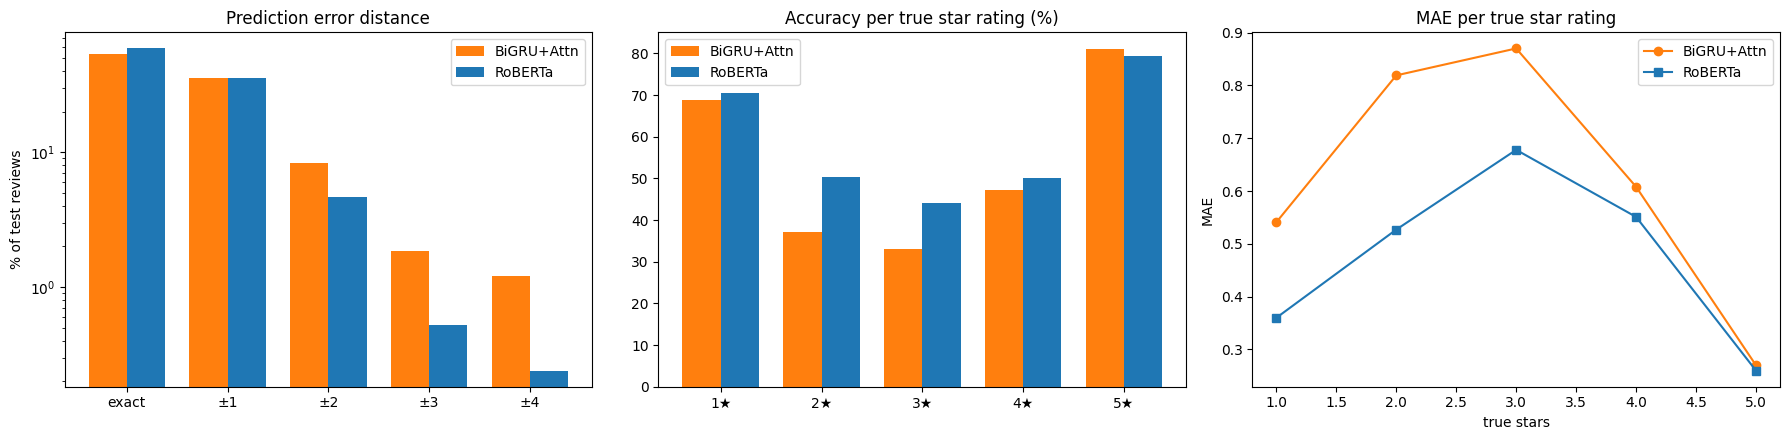

In [21]:
# Error distance distribution + per-star accuracy and MAE
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
dist_b, dist_r = np.abs(te_y - pb), np.abs(te_y - pr)
x = np.arange(5)
ax[0].bar(x - w/2, [100*(dist_b == d).mean() for d in range(5)], w, label="BiGRU+Attn", color="tab:orange")
ax[0].bar(x + w/2, [100*(dist_r == d).mean() for d in range(5)], w, label="RoBERTa", color="tab:blue")
ax[0].set_xticks(x); ax[0].set_xticklabels(["exact", "±1", "±2", "±3", "±4"]); ax[0].set_ylabel("% of test reviews")
ax[0].set_title("Prediction error distance"); ax[0].set_yscale("log"); ax[0].legend()
acc_b = [100*(pb[te_y == c] == c).mean() for c in range(5)]; acc_r = [100*(pr[te_y == c] == c).mean() for c in range(5)]
ax[1].bar(x - w/2, acc_b, w, color="tab:orange", label="BiGRU+Attn"); ax[1].bar(x + w/2, acc_r, w, color="tab:blue", label="RoBERTa")
ax[1].set_xticks(x); ax[1].set_xticklabels([f"{c}★" for c in CLASSES]); ax[1].set_title("Accuracy per true star rating (%)"); ax[1].legend()
mae_b = [dist_b[te_y == c].mean() for c in range(5)]; mae_r = [dist_r[te_y == c].mean() for c in range(5)]
ax[2].plot(CLASSES, mae_b, "o-", c="tab:orange", label="BiGRU+Attn"); ax[2].plot(CLASSES, mae_r, "s-", c="tab:blue", label="RoBERTa")
ax[2].set(title="MAE per true star rating", xlabel="true stars", ylabel="MAE"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/viz_error_analysis.png", dpi=150); plt.show()

,length,model,n,acc,macro_f1,mae
0,≤25,BiGRU+Attn,2334,0.5347,0.5041,0.6311
1,≤25,RoBERTa,2334,0.5651,0.5441,0.5184
2,26-50,BiGRU+Attn,1452,0.5434,0.5395,0.5847
3,26-50,RoBERTa,1452,0.6012,0.6041,0.4483
4,51-100,BiGRU+Attn,908,0.5485,0.5495,0.6013
5,51-100,RoBERTa,908,0.6200,0.6288,0.4229
6,100+,BiGRU+Attn,306,0.4444,0.4447,0.7843
7,100+,RoBERTa,306,0.6176,0.6196,0.4281


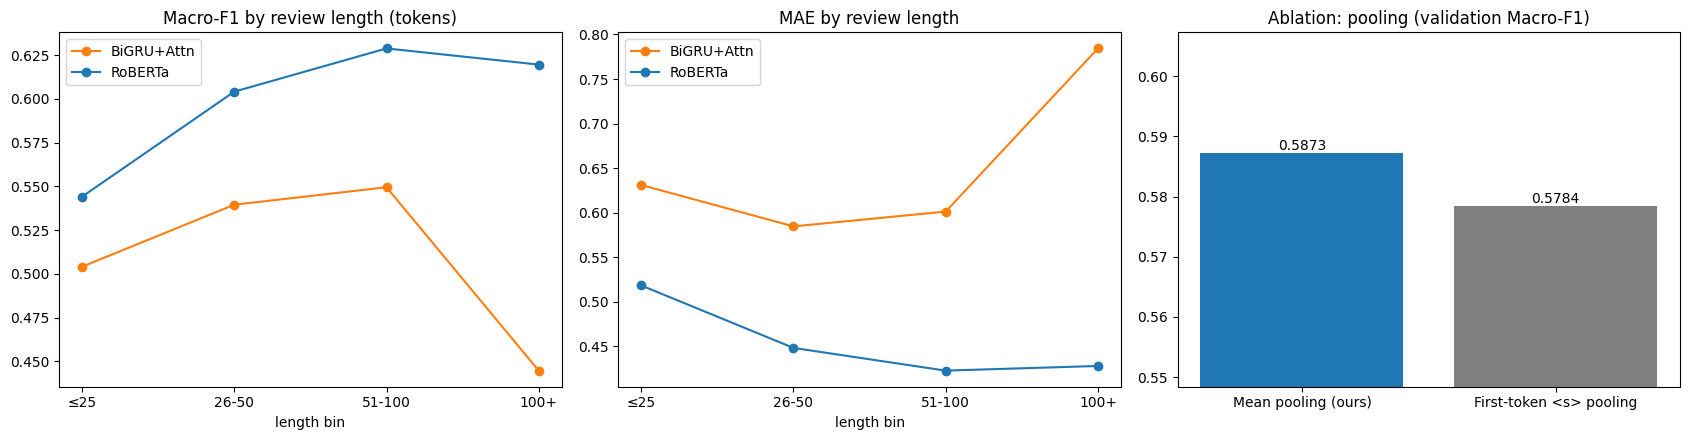

length
100+       306
26-50     1452
51-100     908
≤25       2334 
(reviews per length bin)


In [22]:
# Performance vs. review length + pooling ablation
lens = np.array([len(t) for t in te_tok])
bins = pd.cut(lens, [-1, 25, 50, 100, 10**6], labels=["≤25", "26-50", "51-100", "100+"])
rows = []
for b in bins.categories:
    m = np.asarray(bins == b)
    for name, p in [("BiGRU+Attn", pb), ("RoBERTa", pr)]:
        rows.append(dict(length=b, model=name, n=int(m.sum()), acc=(p[m] == te_y[m]).mean(),
                         macro_f1=f1_score(te_y[m], p[m], average="macro", labels=range(5), zero_division=0),
                         mae=np.abs(te_y[m] - p[m]).mean()))
len_df = pd.DataFrame(rows); display(len_df.round(4)); len_df.to_csv(f"{OUT_DIR}/performance_by_length.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for name, c in [("BiGRU+Attn", "tab:orange"), ("RoBERTa", "tab:blue")]:
    d = len_df[len_df.model == name]
    ax[0].plot(d.length.astype(str), d.macro_f1, "o-", c=c, label=name); ax[1].plot(d.length.astype(str), d.mae, "o-", c=c, label=name)
ax[0].set(title="Macro-F1 by review length (tokens)", xlabel="length bin"); ax[1].set(title="MAE by review length", xlabel="length bin")
ax[0].legend(); ax[1].legend()
ax[2].bar(abl_df["Pooling"], abl_df["Val Macro-F1"], color=["tab:blue", "tab:gray"])
for i, v in enumerate(abl_df["Val Macro-F1"]): ax[2].text(i, v, f"{v:.4f}", ha="center", va="bottom")
ax[2].set_title("Ablation: pooling (validation Macro-F1)"); ax[2].set_ylim(abl_df["Val Macro-F1"].min() - 0.03, abl_df["Val Macro-F1"].max() + 0.02)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/viz_length_and_ablation.png", dpi=150); plt.show()
print(len_df.groupby("length")["n"].first().to_string(), "\n(reviews per length bin)")